# 04 · H2–H4: Employment, protective skills and wage dispersion since ChatGPT

| | Hypothesis | SET-III argument | Brynjolfsson–McAfee anchor |
|---|---|---|---|
| H2 | Employment in more exposed occupations grows more slowly after 2022, more so for direct (substitutable) exposure | §5.2: displacement may outpace job creation | Brynjolfsson, Chandar & Chen (2025); *The Turing Trap* (2022) |
| H3 | Social and leadership ("synchronization") skills buffer the exposure effect | §8: synchronization capability | Deming via *Machine, Platform, Crowd* Ch. 13 |
| H4 | Within exposed occupations, wage dispersion (P90/P10) narrows | §5.2: an uneven transition | Brynjolfsson, Li & Raymond (2025): novices gain most |

**Design.** Occupation and year fixed effects, exposure (z-scored β) interacted with year dummies, May 2022 as the reference year, SEs clustered by occupation. The main sample is the balanced 2021–2025 panel (all on SOC 2018 codes).

**Caveat for the text.** OEWS estimates pool three years of survey panels, and BLS cautions against reading them as a time series. The coefficients describe divergence; they are not causal estimates.

In [1]:
from setiii_common import *
import matplotlib.pyplot as plt
set_style()
p, years = prepare_occ_panel(MAIN_WINDOW, "beta_gpt", balanced=True)
print("years:", years, "| occupations:", p["soc"].nunique(), "| obs:", len(p))
# Exposure components (z-scored per occupation), skill flags
cross = p.drop_duplicates("soc").set_index("soc")
p["e1z"] = p["soc"].map(zscore(cross["alpha_gpt"]))      # direct exposure: the LLM alone halves task time
p["e2z"] = p["soc"].map(zscore(cross["e2_gpt"]))         # needs extra software built on the LLM
p["hs"] = (p["job_zone"] >= 3.5).astype(int)             # Job Zone 4-5
LAST = max(years)

years: [2021, 2022, 2023, 2024, 2025] | occupations: 770 | obs: 3850


## Figure 2. Raw employment change by exposure quintile

Saved figure fig2_employment_by_exposure_quintile


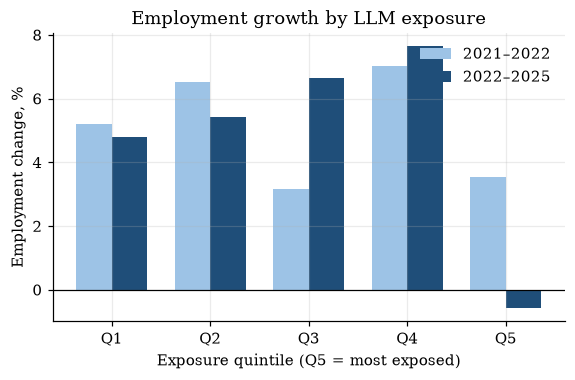

,pre,post,mean_beta
q,,,
1,5.20,4.79,0.04
2,6.53,5.41,0.19
3,3.17,6.64,0.36
4,7.03,7.64,0.49
5,3.54,-0.58,0.70


In [2]:
cross = p[p["year"] == REF_YEAR].set_index("soc")
cross["q"] = weighted_quantile_bins(cross["ez"], cross["w"], 5)
emp = p.pivot_table(index="soc", columns="year", values="tot_emp")
cross["g_pre"] = 100 * (emp[REF_YEAR] / emp[min(years)] - 1)
cross["g_post"] = 100 * (emp[LAST] / emp[REF_YEAR] - 1)
g = cross.groupby("q").apply(lambda d: pd.Series({
    "pre": 100 * (emp.loc[d.index, REF_YEAR].sum() / emp.loc[d.index, min(years)].sum() - 1),
    "post": 100 * (emp.loc[d.index, LAST].sum() / emp.loc[d.index, REF_YEAR].sum() - 1),
    "mean_beta": d["beta_gpt"].mean()}), include_groups=False)
fig, ax = plt.subplots(figsize=(6, 3.4))
x = np.arange(len(g))
ax.bar(x - 0.18, g["pre"], 0.36, color=PALETTE["light"], label=f"{min(years)}–{REF_YEAR}")
ax.bar(x + 0.18, g["post"], 0.36, color=PALETTE["main"], label=f"{REF_YEAR}–{LAST}")
ax.set_xticks(x, [f"Q{i}" for i in g.index]); ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Exposure quintile (Q5 = most exposed)"); ax.set_ylabel("Employment change, %")
ax.set_title("Employment growth by LLM exposure"); ax.legend()
save_fig(fig, "fig2_employment_by_exposure_quintile"); plt.show()
g.round(2)

## H2. Event studies: log employment

lemp         pre-trend p = 0.169 | occupations = 770
lemp_w       pre-trend p = 0.420 | occupations = 770
lemp_major   pre-trend p = 0.466 | occupations = 770
Saved figure fig3_event_study_employment


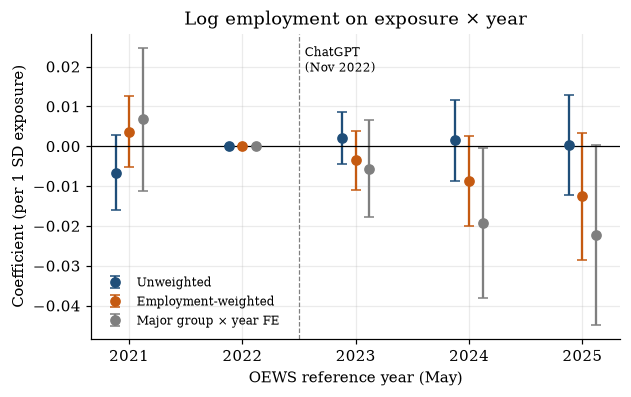

Saved table table_s2_event_study_employment


In [3]:
es = {}
es["lemp"], r_lemp = event_study(p, "lemp", years)
es["lemp_w"], _ = event_study(p, "lemp", years, weights="w")
es["lemp_major"], _ = event_study(p, "lemp", years, fe="major_year")
for k, t in es.items():
    print(f"{k:12s} pre-trend p = {t.attrs['pretrend_p']:.3f} | occupations = {t.attrs['n_soc']}")
plot_event({"Unweighted": es["lemp"], "Employment-weighted": es["lemp_w"],
            "Major group × year FE": es["lemp_major"]},
           "Log employment on exposure × year", "Coefficient (per 1 SD exposure)", "fig3_event_study_employment")
save_table(pd.concat({k: v for k, v in es.items()}), "table_s2_event_study_employment",
           "Event-study coefficients, log employment")

## H2–H4. Pooled difference-in-differences (Table 4)

In [4]:
rows = []
def add(tab):
    rows.append(tab)
    return tab

# H2: average post-2022 effect
add(pooled(p, "lemp", {"ez_post": p.ez * p.post}, label="H2 log employment")[0])
add(pooled(p, "lemp", {"ez_post": p.ez * p.post}, fe="major_year", label="H2 + major×year FE")[0])
add(pooled(p, "lemp", {"ez_post": p.ez * p.post}, weights="w", label="H2 weighted")[0])
# H2b: direct (E1) vs tool-dependent (E2) exposure
add(pooled(p, "lemp", {"e1_post": p.e1z * p.post, "e2_post": p.e2z * p.post}, label="H2b E1 vs E2")[0])
# H2c: are highly skilled professions different?
add(pooled(p, "lemp", {"ez_post": p.ez * p.post, "hs_post": p.hs * p.post,
                       "ez_hs_post": p.ez * p.hs * p.post}, label="H2c high skill")[0])
# H3: protective skills
for idx in ["protective_idx", "sync_idx", "social_idx", "ideation_idx"]:
    add(pooled(p, "lemp", {"ez_post": p.ez * p.post, "P_post": p[idx] * p.post,
                           "ez_P_post": p.ez * p[idx] * p.post}, label=f"H3 {idx}")[0])
# H4: wages and dispersion (drop occupations with a top-coded P90 from P90 models)
pnt = p[~p["p90_topcoded_any"].astype(bool)].copy()
add(pooled(p, "lmed", {"ez_post": p.ez * p.post}, label="H4 log median wage")[0])
add(pooled(pnt, "l9010", {"ez_post": pnt.ez * pnt.post}, label="H4 log P90/P10")[0])
add(pooled(p, "l7525", {"ez_post": p.ez * p.post}, label="H4 log P75/P25")[0])
add(pooled(pnt, "l9010", {"ez_post": pnt.ez * pnt.post, "hs_post": pnt.hs * pnt.post,
                          "ez_hs_post": pnt.ez * pnt.hs * pnt.post}, label="H4 P90/P10 high skill")[0])
t4 = pd.concat(rows)
t4["sig"] = t4["p"].map(stars)
save_table(t4.set_index("model", append=True), "table4_pooled_did", "Pooled DiD: exposure × post-2022")
t4.round(4)

Saved table table4_pooled_did


,model,coef,se,p,ci_low,ci_high,n_obs,sig
ez_post,H2 log employment,0.0046,0.0055,0.3979,-0.0061,0.0154,3850,
ez_post,H2 + major×year FE,-0.0191,0.0094,0.0417,-0.0375,-0.0007,3850,**
ez_post,H2 weighted,-0.0101,0.0071,0.1548,-0.0241,0.0038,3850,
e1_post,H2b E1 vs E2,-0.0109,0.0049,0.0267,-0.0205,-0.0013,3850,**
e2_post,H2b E1 vs E2,0.0184,0.0048,0.0001,0.0089,0.0279,3850,***
ez_post,H2c high skill,-0.0080,0.0073,0.2736,-0.0224,0.0063,3850,
hs_post,H2c high skill,0.0700,0.0124,0.0000,0.0458,0.0943,3850,***
ez_hs_post,H2c high skill,-0.0166,0.0136,0.2229,-0.0432,0.0101,3850,
ez_post,H3 protective_idx,-0.0081,0.0062,0.1933,-0.0203,0.0041,3745,
P_post,H3 protective_idx,0.0399,0.0056,0.0000,0.0290,0.0509,3745,***


## H4. Event studies: wages and dispersion

Saved figure fig4_event_study_wages


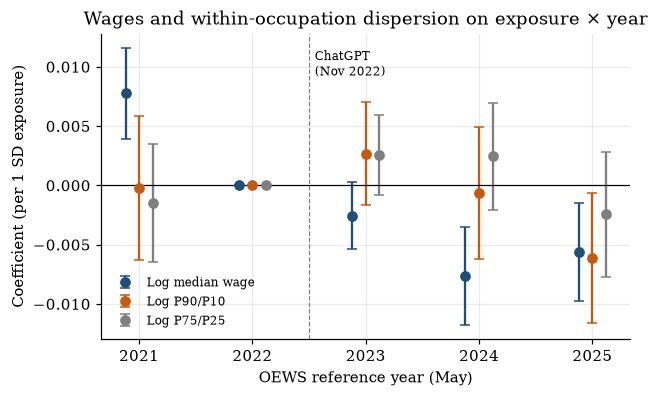

lmed   pre-trend p = 0.000
l9010  pre-trend p = 0.946
l7525  pre-trend p = 0.561


In [5]:
es["lmed"], _ = event_study(p, "lmed", years)
es["l9010"], _ = event_study(pnt, "l9010", years)
es["l7525"], _ = event_study(p, "l7525", years)
plot_event({"Log median wage": es["lmed"], "Log P90/P10": es["l9010"], "Log P75/P25": es["l7525"]},
           "Wages and within-occupation dispersion on exposure × year",
           "Coefficient (per 1 SD exposure)", "fig4_event_study_wages")
for k in ["lmed", "l9010", "l7525"]:
    print(f"{k:6s} pre-trend p = {es[k].attrs['pretrend_p']:.3f}")

## Figure 5. Protective skills: predicted post-2022 effect of exposure by skill level

Saved figure fig5_protective_skills_margins


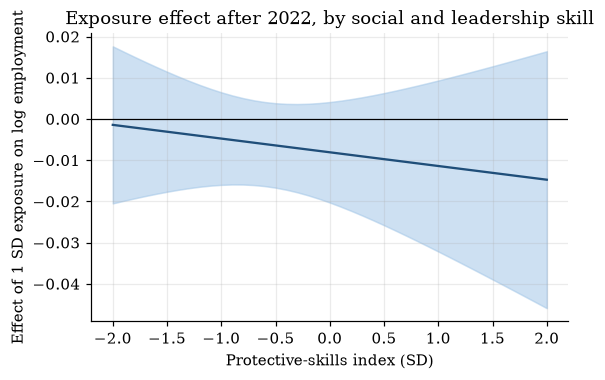

In [6]:
tab, r = pooled(p, "lemp", {"ez_post": p.ez * p.post, "P_post": p.protective_idx * p.post,
                             "ez_P_post": p.ez * p.protective_idx * p.post})
grid = np.linspace(-2, 2, 41)
b, V = r.params, r.cov_params()
eff = b["ez_post"] + b["ez_P_post"] * grid
se = np.sqrt(V.loc["ez_post", "ez_post"] + grid**2 * V.loc["ez_P_post", "ez_P_post"]
             + 2 * grid * V.loc["ez_post", "ez_P_post"])
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(grid, eff, color=PALETTE["main"])
ax.fill_between(grid, eff - 1.96 * se, eff + 1.96 * se, color=PALETTE["light"], alpha=0.5)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Protective-skills index (SD)"); ax.set_ylabel("Effect of 1 SD exposure on log employment")
ax.set_title("Exposure effect after 2022, by social and leadership skill")
save_fig(fig, "fig5_protective_skills_margins"); plt.show()

## Numbers for the paper

In [7]:
def pick(model, term):
    r = t4[(t4["model"] == model)].loc[term]
    return {"coef": round(float(r["coef"]), 4), "se": round(float(r["se"]), 4), "p": float(r["p"])}

res = {
    "years": years, "n_occupations": int(p["soc"].nunique()), "n_obs": int(len(p)),
    "pretrend_p_lemp": es["lemp"].attrs["pretrend_p"],
    "H2_ez_post": pick("H2 log employment", "ez_post"),
    "H2_major_year": pick("H2 + major×year FE", "ez_post"),
    "H2b_e1_post": pick("H2b E1 vs E2", "e1_post"), "H2b_e2_post": pick("H2b E1 vs E2", "e2_post"),
    "H2c_ez_hs_post": pick("H2c high skill", "ez_hs_post"),
    "H3_ez_P_post": pick("H3 protective_idx", "ez_P_post"),
    "H3_sync": pick("H3 sync_idx", "ez_P_post"),
    "H4_lmed": pick("H4 log median wage", "ez_post"),
    "H4_l9010": pick("H4 log P90/P10", "ez_post"),
    "H4_l7525": pick("H4 log P75/P25", "ez_post"),
    "employment_growth_by_quintile": g[["pre", "post"]].round(2).to_dict(),
}
v = lambda d, sign: "supported" if (d["p"] < 0.05 and np.sign(d["coef"]) == sign) else "not supported"
res["verdict"] = {"H2": v(res["H2_ez_post"], -1), "H3": v(res["H3_ez_P_post"], 1),
                  "H4": v(res["H4_l9010"], -1)}
(DATA_FIN / "results_h2_h4.json").write_text(json.dumps(res, indent=2, default=str))
print(json.dumps(res, indent=2, default=str))

{
  "years": [
    2021,
    2022,
    2023,
    2024,
    2025
  ],
  "n_occupations": 770,
  "n_obs": 3850,
  "pretrend_p_lemp": 0.16890589799530384,
  "H2_ez_post": {
    "coef": 0.0046,
    "se": 0.0055,
    "p": 0.3978761107828188
  },
  "H2_major_year": {
    "coef": -0.0191,
    "se": 0.0094,
    "p": 0.04173531377989987
  },
  "H2b_e1_post": {
    "coef": -0.0109,
    "se": 0.0049,
    "p": 0.026679962005942068
  },
  "H2b_e2_post": {
    "coef": 0.0184,
    "se": 0.0048,
    "p": 0.00014016319025414507
  },
  "H2c_ez_hs_post": {
    "coef": -0.0166,
    "se": 0.0136,
    "p": 0.22292634286565993
  },
  "H3_ez_P_post": {
    "coef": -0.0033,
    "se": 0.0058,
    "p": 0.5668273549203184
  },
  "H3_sync": {
    "coef": 0.0056,
    "se": 0.0054,
    "p": 0.3045213151296635
  },
  "H4_lmed": {
    "coef": -0.0091,
    "se": 0.0018,
    "p": 3.967224517533249e-07
  },
  "H4_l9010": {
    "coef": -0.0013,
    "se": 0.0023,
    "p": 0.5885712471648359
  },
  "H4_l7525": {
    "coef":